In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 2. Análisis exploratorio de datos

El análisis exploratorio tiene un propósito concreto: convertir lo que se observa en los datos en decisiones de preprocesamiento y de arquitectura, y detectar a tiempo los riesgos de fuga. Por eso cada análisis cierra con una interpretación técnica, y la sección 2.9 reúne en una tabla la decisión, el impacto en la arquitectura y el riesgo de cada hallazgo.

Las agregaciones de conteo y CTR se calcularon sobre las 40.428.967 filas con DuckDB, fuera de memoria. Las medidas de asociación y el PSI usan una muestra aleatoria de 2.000.000 de filas de entrenamiento, por el límite de 16 GB de RAM.

## 2.1 Carga eficiente y calidad de los datos

El CSV se convirtió una sola vez a Parquet particionado por día con DuckDB, y desde ahí cada análisis lee solo las columnas y los días que necesita. La conversión verificó el conteo total de filas (40.428.967), la presencia de los diez días y la ausencia de valores nulos en las 24 columnas originales.

In [2]:
dias = pd.read_csv(ART / "eda" / "ctr_by_day.csv")
dias["fecha"] = pd.to_datetime("2014-10-" + dias["day"].astype(str))
nombres = {0: "lunes", 1: "martes", 2: "miércoles", 3: "jueves", 4: "viernes", 5: "sábado", 6: "domingo"}
dias["dia_semana"] = dias["fecha"].dt.dayofweek.map(nombres)
dias["particion"] = np.select([dias["day"] <= 28, dias["day"] == 29], ["train", "validación"], "prueba")
dias["ctr_pct"] = 100 * dias["ctr"]
tabla(dias[["day", "dia_semana", "particion", "n"]].rename(
    columns={"day": "día", "dia_semana": "día de la semana", "particion": "partición", "n": "impresiones"}), d=2)

día,día de la semana,partición,impresiones
21,martes,train,4.122.995
22,miércoles,train,5.337.126
23,jueves,train,3.870.752
24,viernes,train,3.335.302
25,sábado,train,3.363.122
26,domingo,train,3.835.892
27,lunes,train,3.225.010
28,martes,train,5.287.222
29,miércoles,validación,3.832.608
30,jueves,prueba,4.218.938


## 2.2 Distribución de la variable objetivo

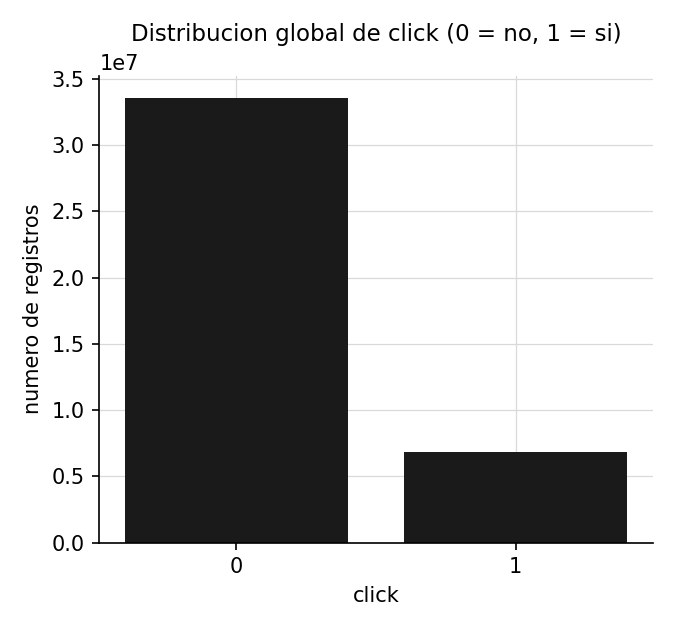

In [3]:
figura(ART / "eda" / "click_overall.png", 520)

**Interpretación.** De las 40.428.967 impresiones, 33.563.901 (83,02 %) no tuvieron clic y 6.865.066 (16,98 %) sí lo tuvieron. Es un desbalance moderado, con 4,89 negativos por cada positivo, lejos de los escenarios extremos de detección de fraude donde la clase positiva no llega al 1 %.

Esto significa que un clasificador trivial que siempre predice "no clic" tendría un accuracy de 83 %, sin ningún valor práctico. Por eso el accuracy no puede ser la métrica de referencia. El ROC AUC sí es apropiado como métrica primaria, porque mide la probabilidad de que un positivo reciba un puntaje mayor que un negativo y no depende de la tasa base, mientras que la PR AUC tiene como referencia de azar la propia tasa base (0,17), así que expone mejor el desempeño sobre la clase minoritaria.

Por tal motivo, se opta por ROC AUC como métrica primaria y PR AUC como secundaria, y por elegir el umbral de decisión en validación maximizando F1, en lugar de usar 0,5. La ponderación de clases se evalúa como ablación (capítulo 9), tal como pide el enunciado.

## 2.3 Tasa de clics por día

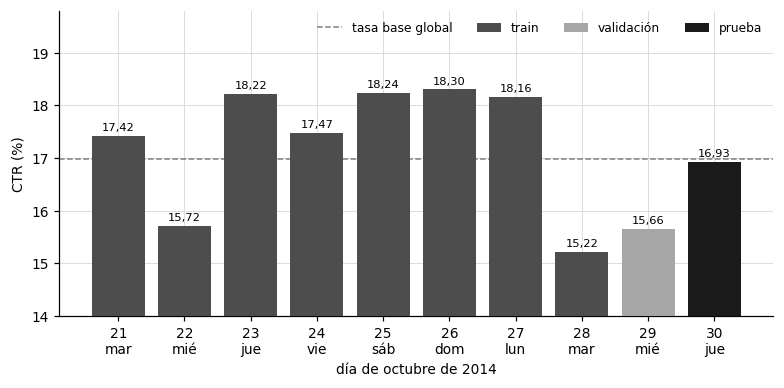

In [4]:
fig, ax = new_figure((7.2, 3.6))
tonos = {"train": "#4d4d4d", "validación": "#a6a6a6", "prueba": "#1a1a1a"}
for p, sub in dias.groupby("particion", sort=False):
    ax.bar(sub["day"], sub["ctr_pct"], color=tonos[p], label=p, zorder=3)
for d, v in zip(dias["day"], dias["ctr_pct"]):
    ax.text(d, v + 0.06, es(v, 2), ha="center", va="bottom", fontsize=7.5)
ax.axhline(100 * 0.16980562, color="#808080", linestyle="--", linewidth=1, label="tasa base global")
ax.set_ylim(14, 19.8); ax.set_xticks(dias["day"])
ax.set_xticklabels([f"{d}\n{w[:3]}" for d, w in zip(dias["day"], dias["dia_semana"])])
ax.set_xlabel("día de octubre de 2014"); ax.set_ylabel("CTR (%)")
ax.legend(frameon=False, fontsize=8, ncol=4); plt.tight_layout(); plt.show()

**Interpretación.** El CTR diario oscila entre 15,22 % (día 28, martes) y 18,30 % (día 26, domingo), una amplitud de 3,1 puntos porcentuales sobre una media de 17 %. Los dos días de mayor volumen, el 22 y el 28 (más de 5,2 millones de impresiones cada uno), son también los de menor CTR, 15,72 % y 15,22 %. La validación (día 29) tiene un CTR de 15,66 % y la prueba (día 30) de 16,93 %.

Lo anterior indica que el CTR tiene deriva temporal: varía de un día a otro en una magnitud comparable a las diferencias entre modelos que interesa detectar. Hay que tener en cuenta que, si la partición fuera aleatoria, las mismas condiciones de un día aparecerían a la vez en entrenamiento y en prueba, y el modelo se evaluaría sobre un futuro que ya conoce. Además, la validación tiene un CTR 1,3 puntos más bajo que la prueba, así que un umbral calibrado sobre el día 29 puede quedar algo desplazado frente al día 30.

Por ello, se mantiene la partición temporal que fija el enunciado (train 21 a 28, validación 29, prueba 30), y se reportan métricas de calibración (log loss, Brier, ECE), que son las que capturan ese desplazamiento entre el CTR de validación y el de prueba.

## 2.4 Tasa de clics por hora y franja horaria

La hora del día, `hour_of_day`, es la principal variable numérica derivada del campo `hour`. El panel izquierdo muestra su distribución, es decir, el volumen de impresiones por hora, y el derecho su CTR.

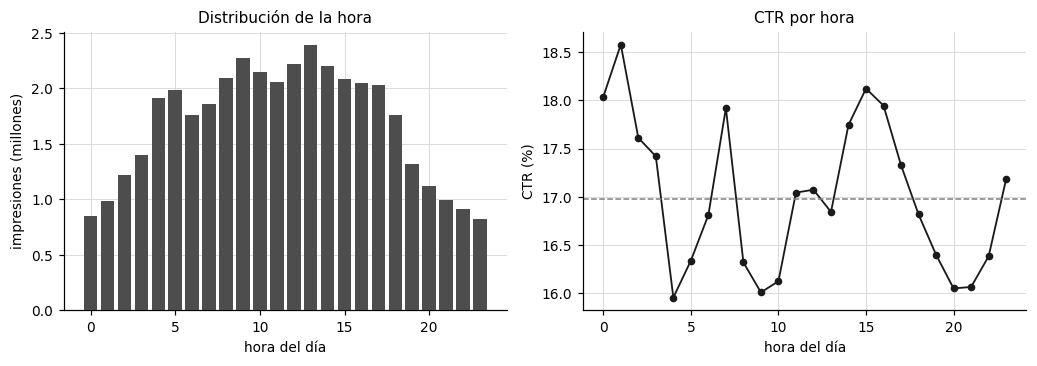

franja,impresiones,CTR (%)
tarde,12.970.206,"17,49"
madrugada,8.347.162,"17,05"
mañana,12.194.906,"16,66"
noche,6.916.693,"16,49"


In [5]:
horas = pd.read_csv(ART / "eda" / "ctr_by_hour.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.4))
for a in (a1, a2):
    a.grid(True, color="#d9d9d9", linewidth=0.6, zorder=0); a.set_axisbelow(True)
    for s in ("top", "right"): a.spines[s].set_visible(False)
a1.bar(horas["hour_of_day"], horas["n"] / 1e6, color="#4d4d4d", zorder=3)
a1.set_xlabel("hora del día"); a1.set_ylabel("impresiones (millones)"); a1.set_title("Distribución de la hora", fontsize=10)
a2.plot(horas["hour_of_day"], 100 * horas["ctr"], color="#1a1a1a", marker="o", markersize=4, linewidth=1.2)
a2.axhline(100 * 0.16980562, color="#808080", linestyle="--", linewidth=1)
a2.set_xlabel("hora del día"); a2.set_ylabel("CTR (%)"); a2.set_title("CTR por hora", fontsize=10)
plt.tight_layout(); plt.show()
franjas = pd.read_csv(ART / "eda" / "ctr_by_franja.csv")
franjas["ctr_pct"] = 100 * franjas["ctr"]
franjas["franja_horaria"] = franjas["franja_horaria"].replace({"manana": "mañana"})
tabla(franjas[["franja_horaria", "n", "ctr_pct"]].rename(columns={"franja_horaria": "franja", "n": "impresiones", "ctr_pct": "CTR (%)"}), d=2)

**Interpretación.** El volumen de impresiones sigue el ciclo diario de uso: es mínimo a las 23 horas (818.771 impresiones) y máximo a las 13 horas (2.388.730). El CTR, en cambio, varía poco, entre 15,96 % a las 4 horas y 18,58 % a la 1 hora, con una desviación estándar de 0,78 puntos entre las 24 horas. Por franja, la tarde tiene el CTR más alto (17,49 %) y la noche el más bajo (16,49 %).

Es decir, la hora explica mucho del volumen pero poco de la probabilidad de clic: un rango de 2,6 puntos alrededor de una media de 17 % es una señal débil frente a la que aportan el sitio, la aplicación o el dispositivo (sección 2.7). Así mismo, la relación entre hora y CTR no es monótona, porque el máximo está a la 1 y el mínimo a las 4, así que tratar la hora como variable numérica continua en un modelo lineal no la aprovecharía.

En consecuencia, si la hora se usa como predictor, debe entrar como categórica y no escalada como numérica. Hay que declarar que el conjunto de variables del experimento principal se limitó a las 12 categóricas de sitio, aplicación y dispositivo, y no incluyó la hora ni las columnas `C1` y `C14` a `C21`. Esa exclusión no se fijó a partir de esta evidencia, así que su efecto se cuantifica como una variante de las ablaciones, con esas columnas como categóricas dentro del hashing (capítulo 9). La transformación logarítmica que el enunciado propone para numéricas de cola pesada no aplica: la hora es acotada y cíclica, y las columnas `C*` son códigos anonimizados, no magnitudes (sección 2.7).

## 2.5 Frecuencias de las principales categóricas

La tabla muestra, para cada variable de baja cardinalidad, sus tres categorías más frecuentes con su volumen, su participación en el total y su CTR.

In [6]:
res = []
for v in ("device_type", "device_conn_type", "banner_pos", "app_category", "site_category"):
    f = pd.read_csv(ART / "eda" / f"freq_{v}.csv").head(3)
    for _, r in f.iterrows():
        val = r[v]
        val = str(int(val)) if isinstance(val, (int, float, np.floating)) else str(val)
        res.append((v, val, int(r["n"]), 100 * r["n"] / 40428967, 100 * r["ctr"]))
tabla(pd.DataFrame(res, columns=["variable", "categoría", "impresiones", "% del total", "CTR (%)"]), d=2, enteros=("impresiones",))

variable,categoría,impresiones,% del total,CTR (%)
device_type,1,37.304.667,"92,27","16,92"
device_type,0,2.220.812,"5,49","21,07"
device_type,4,774.272,"1,92","9,54"
device_conn_type,0,34.886.838,"86,29","18,11"
device_conn_type,2,3.317.443,"8,21","13,53"
device_conn_type,3,2.181.796,"5,40","4,40"
banner_pos,0,29.109.590,"72,00","16,43"
banner_pos,1,11.247.282,"27,82","18,36"
banner_pos,7,43.577,"0,11","32,01"
app_category,07d7df22,26.165.592,"64,72","19,91"


**Interpretación.** Las categóricas de baja cardinalidad tienen distribuciones muy concentradas y CTR muy distintos entre categorías. El tipo de dispositivo 1 cubre el 92,3 % de las impresiones con un CTR de 16,92 %, mientras que el tipo 0 tiene un CTR de 21,07 %. En el tipo de conexión, la categoría 0 (86,3 % del total) tiene un CTR de 18,11 % y la 3 apenas 4,40 %. En la posición del anuncio, la 7 llega a 32,01 % con solo 43.577 impresiones, y una categoría de sitio (`3e814130`) alcanza 28,30 % con 3.050.306.

De esta forma, estas variables discriminan bien aunque tengan pocas categorías: una diferencia de 18,11 % frente a 4,40 % es una razón de 4 a 1 en la probabilidad de clic. Hay que tener en cuenta que las categorías con muy pocas impresiones, como la posición 7, producen estimaciones de CTR con mucha varianza: con 43.577 observaciones el error estándar es cercano a 0,2 puntos, pero en categorías de pocas decenas sería de varios puntos, y un codificador que las use sin suavizar memorizaría ruido.

Por lo anterior, conviene agrupar en `__RARE__` las categorías con menos de 20 apariciones en entrenamiento, y usar target encoding con suavizado bayesiano hacia la media global (capítulo 3), de modo que las categorías poco frecuentes se acerquen a la tasa base en lugar de tomar valores extremos.

## 2.6 Cardinalidad y cola larga

La curva de frecuencia acumulada muestra qué fracción de las impresiones cubren las categorías más frecuentes de cada variable de alta cardinalidad. La tabla reporta además la proporción de categorías vistas una sola vez, que el enunciado pide de forma explícita.

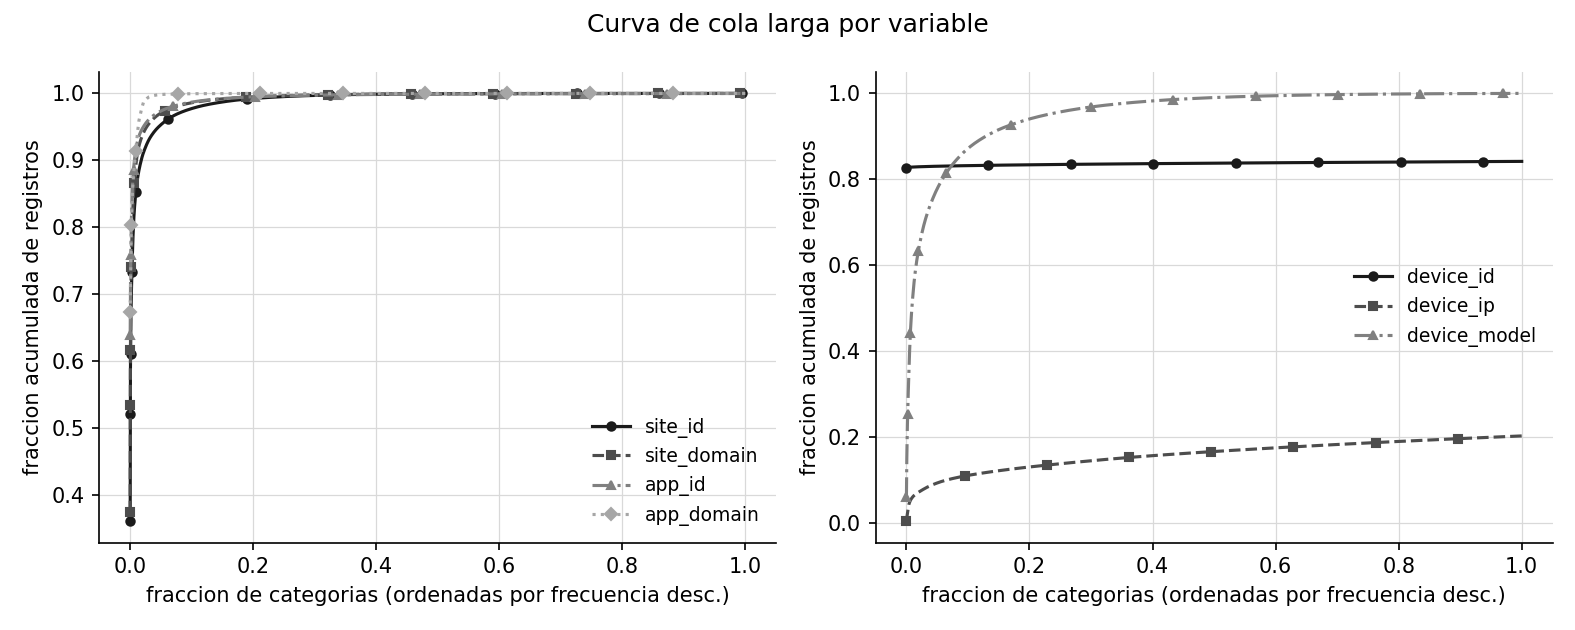

variable,categorías,% vistas una vez,categorías para el 80 % de la masa
site_id,4.737,"11,97",26
site_domain,7.745,"25,07",19
app_id,8.552,"19,11",10
app_domain,559,"23,43",2
device_id,2.686.408,"62,91",1
device_ip,6.729.486,"49,42",1.470.152
device_model,8.251,"9,82",294


In [7]:
figura(ART / "eda" / "cola_larga.png", 760)
c = pd.read_csv(ART / "eda" / "cardinalidad_resumen.csv")
c["pct_singletons"] = 100 * c["pct_singletons"]
tabla(c.rename(columns={"columna": "variable", "n_categorias": "categorías", "pct_singletons": "% vistas una vez",
                        "categorias_para_80pct_masa": "categorías para el 80 % de la masa"}), d=2,
      enteros=("categorías", "categorías para el 80 % de la masa"))

**Interpretación.** `device_ip` tiene 6.729.486 categorías, de las que el 49,4 % aparece una sola vez, y necesita 1.470.152 categorías para cubrir el 80 % de las impresiones. `device_id` tiene 2.686.408 categorías, con 62,9 % vistas una vez, pero una sola categoría cubre por sí sola más del 80 % de la masa: es un valor de relleno, un artefacto conocido de Avazu para los dispositivos sin identificador. En el otro extremo, `site_id` y `app_id` tienen miles de categorías, pero 26 y 10 de ellas, respectivamente, cubren el 80 % del tráfico.

Esto quiere decir que hay dos tipos de alta cardinalidad. En `site_id`, `app_id` o `site_domain` la masa se concentra en pocas categorías estables, que el modelo puede aprender. En `device_ip` y `device_id`, la mitad o más de las categorías no se vuelve a ver, así que no tienen poder de generalización: una IP que aparece una vez en entrenamiento no aporta nada al predecir el día 30. El enunciado lo advierte de forma explícita: un one-hot sobre `device_ip` y `device_id` haría que la capa de entrada del MLP tuviera millones de neuronas.

Por esta razón, lo indicado es descartar el one-hot y usar hashing de dimensión fija, que acota la entrada a $2^{12}$ columnas sin importar cuántas categorías existan, combinado con la agrupación de raras, que manda las categorías vistas una vez a un solo token. La dimensión del hashing se trata como factor experimental en las ablaciones.

## 2.7 Asociación con la variable objetivo

### Información mutua y su sesgo de estimación

La información mutua entre una variable $X$ con $K$ categorías y el objetivo $Y$ se estimó con el estimador directo (*plug-in*), que reemplaza las probabilidades por frecuencias observadas. Ese estimador tiene un sesgo positivo conocido, de orden

$$\mathbb{E}[\hat I(X;Y)] - I(X;Y) \approx \frac{(K-1)(|\mathcal{Y}|-1)}{2N} \ \text{nats},$$

donde $N$ es el tamaño de la muestra y $|\mathcal{Y}| = 2$ {cite}`paninski2003estimation`. Para variables con cientos de miles de categorías en una muestra de 2.000.000 de filas, ese sesgo no es despreciable, así que la tabla lo reporta junto al valor estimado. El número de categorías distintas por variable se midió en una muestra de entrenamiento del mismo tamaño; en las variables de baja cardinalidad, con unas decenas de categorías, el sesgo es del orden de $10^{-5}$ y se omite.

In [8]:
mi = pd.read_csv(ART / "eda" / "informacion_mutua.csv")
k_muestra = {"device_ip": 929021, "device_id": 274882, "site_id": 3006, "app_id": 3983, "site_domain": 3520, "device_model": 5753}
mi["K_en_muestra_2M"] = mi["columna"].map(k_muestra)
mi["sesgo_esperado"] = (mi["K_en_muestra_2M"] - 1) / (2 * 2_000_000)
mi["IM_corregida"] = mi["informacion_mutua"] - mi["sesgo_esperado"]
tabla(mi.rename(columns={"columna": "variable", "informacion_mutua": "IM estimada (nats)",
                         "K_en_muestra_2M": "K en la muestra", "sesgo_esperado": "sesgo esperado",
                         "IM_corregida": "IM corregida"}), d=4, enteros=("K en la muestra",))

variable,IM estimada (nats),K en la muestra,sesgo esperado,IM corregida
device_ip,"0,2597",929.021,"0,2323","0,0274"
device_id,"0,0679",274.882,"0,0687","-0,0008"
site_id,"0,0369",3.006,"0,0008","0,0362"
site_domain,"0,0331",3.520,"0,0009","0,0322"
app_id,"0,0234",3.983,"0,0010","0,0224"
device_model,"0,0197",5.753,"0,0014","0,0183"
app_domain,"0,0124",,,
site_category,"0,0080",,,
app_category,"0,0072",,,
device_conn_type,"0,0052",,,


**Interpretación.** El estimador directo ubica a `device_ip` (0,2597 nats) y a `device_id` (0,0679) muy por encima de las demás variables. Sin embargo, en una muestra de 2.000.000 de filas hay 929.021 IP distintas, lo que produce un sesgo esperado de 0,2323 nats, y 274.882 identificadores de dispositivo, con un sesgo de 0,0687. Al descontar el sesgo, a `device_ip` le quedan unos 0,027 nats y `device_id` queda en cero. `site_id` (0,0369), `site_domain` (0,0331) y `app_id` (0,0234), en cambio, tienen sesgos menores a 0,0011, así que su señal es real.

Lo anterior indica que el primer lugar de `device_ip` es en su mayor parte un artefacto de la cardinalidad: con tantas categorías vistas una vez, cada una "predice" sin error su propio clic, y el estimador lo confunde con dependencia. Después de la corrección, el ordenamiento cambia: encabezan `site_id` (0,036) y `site_domain` (0,032), seguidos por `device_ip` (0,027), `app_id` (0,022) y `device_model` (0,018). El capítulo 8 confirma que la señal está en el sitio y la aplicación con la importancia por permutación sobre el modelo entrenado, donde los codificadores de `app_id` y `site_id` encabezan la lista.

Por ello, se recomienda no descartar ni privilegiar variables con base en la información mutua sin corregir. Las de alta cardinalidad se conservan, pero con agrupación de raras y suavizado, que es lo que evita que el modelo aprenda el mismo artefacto que infla el estimador.

### V de Cramér entre categóricas de baja cardinalidad

La V de Cramér, $V = \sqrt{\chi^2 / (N \cdot \min(r-1, c-1))}$, mide la asociación entre dos categóricas en una escala de 0 a 1 {cite}`cramer1946mathematical`. Se usa para detectar redundancia entre predictores.

In [9]:
cv = pd.read_csv(ART / "eda" / "cramers_v.csv").sort_values("cramers_v", ascending=False)
tabla(cv.rename(columns={"var_a": "variable A", "var_b": "variable B", "cramers_v": "V de Cramér"}), d=3)

variable A,variable B,V de Cramér
app_category,device_conn_type,"0,299"
banner_pos,site_category,"0,276"
site_category,device_conn_type,"0,204"
site_category,app_category,"0,198"
site_category,device_type,"0,179"
banner_pos,app_category,"0,177"
banner_pos,device_type,"0,173"
app_category,device_type,"0,152"
device_type,device_conn_type,"0,132"
banner_pos,device_conn_type,"0,084"


**Interpretación.** La asociación más alta es entre `app_category` y `device_conn_type`, con $V = 0{,}299$, seguida de `banner_pos` y `site_category` ($V = 0{,}276$). Las demás parejas están entre 0,08 y 0,20, y ninguna supera 0,30.

Así mismo, valores de ese orden indican una asociación moderada, no redundancia: ninguna variable se puede reconstruir a partir de otra, porque eso requeriría valores cercanos a 1. La asociación entre categoría de la aplicación y tipo de conexión tiene sentido operativo, porque ciertos tipos de aplicación se usan sobre todo con wifi o con datos móviles.

Por tanto, corresponde conservar todas las categóricas de baja cardinalidad, sin eliminar ninguna por colinealidad. Una asociación moderada entre predictores no afecta a un MLP ni a los árboles potenciados como afectaría a la interpretación de los coeficientes de una regresión logística.

### Correlación de Spearman de las columnas anonimizadas

Las columnas `C1` y `C14` a `C21` vienen como enteros. La correlación de Spearman con `click` verifica si su orden numérico contiene información monótona.

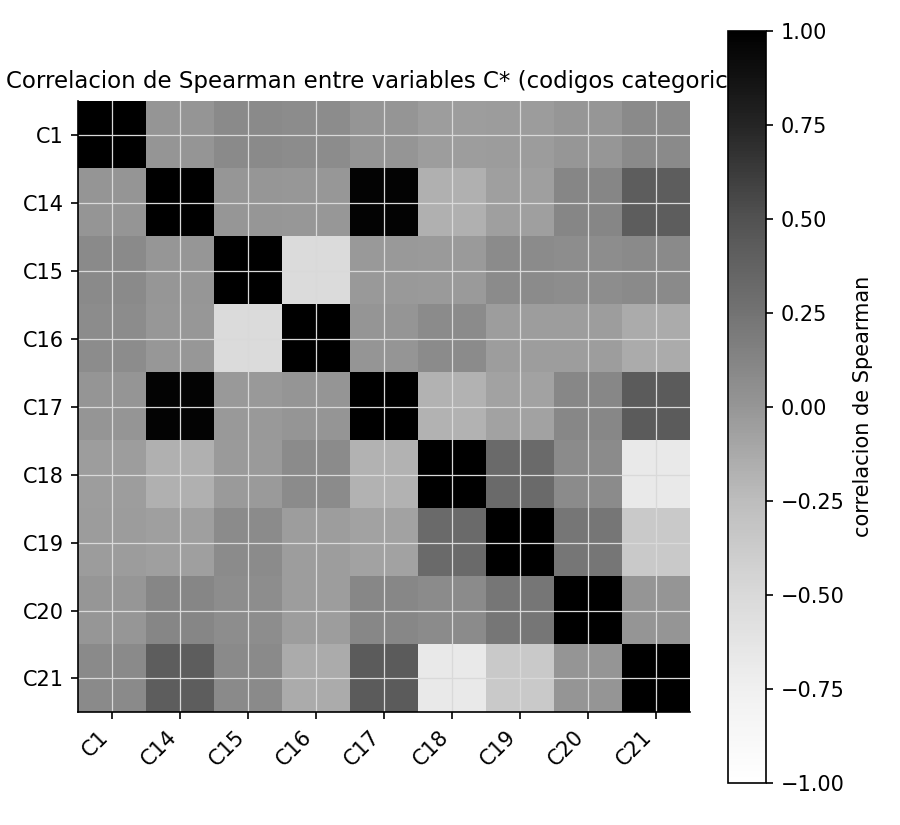

variable,rho de Spearman,p-valor
C1,"-0,0378","0,0000"
C14,"-0,0750","0,0000"
C15,"-0,1178","0,0000"
C16,"0,1348","0,0000"
C17,"-0,0673","0,0000"
C18,"0,0105","0,0000"
C19,"-0,0170","0,0000"
C20,"-0,0693","0,0000"
C21,"-0,0816","0,0000"


In [10]:
figura(ART / "eda" / "correlacion_numeric_like.png", 560)
sp = pd.read_csv(ART / "eda" / "spearman_numeric_like.csv")
tabla(sp.rename(columns={"columna": "variable", "spearman_rho": "rho de Spearman", "p_valor": "p-valor"}), d=4)

**Interpretación.** Todas las correlaciones con `click` son débiles: la mayor en valor absoluto es la de `C16` ($\rho = 0{,}135$), seguida de `C15` ($-0{,}118$), y el resto está por debajo de 0,08. Los $p$-valores son prácticamente cero en todas, incluso en `C18` con $\rho = 0{,}011$.

Sin embargo, con 2.000.000 de observaciones cualquier correlación distinta de cero resulta significativa, porque el error estándar de $\rho$ es del orden de $1/\sqrt{N} \approx 0{,}0007$. La significancia aquí no dice nada de la relevancia práctica. Además, estas columnas son códigos anonimizados, y no hay razón para que el orden de sus valores tenga sentido: el código 320 no es "más" que el 300.

De ahí que, si se usan, deban entrar como categóricas y no como numéricas escaladas, sin transformación logarítmica ni `StandardScaler`, que no tienen sentido estadístico sobre identificadores. Una correlación de Spearman débil no descarta su utilidad como categóricas, porque Spearman solo mide relaciones monótonas con el orden de los códigos. Como el experimento principal no las incluyó, la ablación del capítulo 9 mide su aporte dentro del hashing.

## 2.8 Deriva entre entrenamiento y prueba

El índice de estabilidad poblacional compara la distribución de cada variable entre entrenamiento (proporciones $p_i$) y prueba (proporciones $q_i$):

$$\mathrm{PSI} = \sum_i (q_i - p_i) \ln\frac{q_i}{p_i}.$$

La convención usual en riesgo de crédito es leer valores menores a 0,10 como estabilidad, entre 0,10 y 0,25 como cambio moderado y mayores a 0,25 como cambio significativo {cite}`siddiqi2006credit`.

In [11]:
psi = pd.read_csv(ART / "eda" / "psi_train_vs_test.csv")
psi["lectura"] = pd.cut(psi["psi"], [-1, 0.10, 0.25, 99], labels=["estable", "moderado", "significativo"])
tabla(psi.rename(columns={"columna": "variable", "psi": "PSI"}), d=4)

variable,PSI,lectura
app_category,"0,1843",moderado
site_category,"0,0644",estable
hour_of_day,"0,0439",estable
device_conn_type,"0,0238",estable
banner_pos,"0,0134",estable
device_type,"0,0115",estable
franja_horaria,"0,0100",estable


**Interpretación.** Solo `app_category` supera el umbral de estabilidad, con un PSI de 0,184, que cae en la franja de cambio moderado. Le siguen `site_category` (0,064) y la hora del día (0,044), y las demás variables están por debajo de 0,025.

En ese sentido, la mezcla de tipos de aplicación del día 30 es distinta de la de los días 21 a 28. Como `app_category` tiene CTR muy diferentes entre categorías (19,91 % en la principal frente a 10,81 % en la segunda, sección 2.5), un cambio en su mezcla mueve la tasa de clics esperada aunque el comportamiento dentro de cada categoría no cambie. Esto es una amenaza a la validez externa que conviene tener presente: el desempeño en el día 30 depende en parte de esa mezcla.

Con base en esto, se propone mantener la partición temporal sin ajustes, porque precisamente mide el desempeño bajo esta deriva real, y reportar la calibración en prueba para cuantificar su efecto. La deriva se retoma como amenaza a la validez en el capítulo 10.

## 2.9 Síntesis: decisión, impacto y riesgo por hallazgo

| Hallazgo | Decisión de preprocesamiento | Impacto en la arquitectura | Riesgo, incluida la fuga |
|---|---|---|---|
| Desbalance de 4,89 a 1 (CTR de 16,98 %) | Umbral elegido en validación; ponderación como ablación | ROC AUC y PR AUC como métricas; salida con probabilidad calibrable | Usar el umbral de 0,5; elegir el umbral mirando prueba |
| Deriva diaria del CTR (15,22 % a 18,30 %) | Partición temporal 21-28 / 29 / 30 | Ninguno en el modelo; sí en el protocolo de evaluación | Partición aleatoria, que sobreestima el desempeño |
| Hora con relación no monótona y débil | Si se usa, como categórica; no incluida en el experimento principal | Sin rama numérica para la hora | Omitir una señal útil; se mide en la ablación |
| Categorías raras con CTR inestable | Token `__RARE__` con umbral 20, ajustado en train | Menos columnas efectivas en el hashing | Fijar el umbral con validación o prueba |
| Alta cardinalidad (hasta 6,7 millones de categorías) | Hashing $2^{12}$ más frecuencia y target encoding | Entrada de dimensión fija, sin one-hot | Target encoding sin validación cruzada interna, que filtra la etiqueta |
| IM de `device_ip` y `device_id` inflada por sesgo | No seleccionar variables por IM sin corregir | Se conservan todas, con suavizado | Confundir cardinalidad con señal |
| Asociación moderada entre categóricas ($V \le 0{,}30$) | Conservar todas | Ninguno | Bajo |
| Columnas `C*` anonimizadas, sin orden con sentido | Si se usan, como categóricas; no incluidas en el experimento principal | Sin escalado ni logaritmo | Darles semántica numérica; omitir señal útil (se mide en la ablación) |
| Deriva moderada de `app_category` (PSI = 0,184) | Ninguna adicional | Reportar calibración en prueba | Validez externa limitada al día 30 |